# *ML03: Huấn luyện mô hình Random Forest cho FiveDataset*


### Bước 1. Import thư viện và khởi tạo thư mục output


In [1]:

import os
import re
import random
import zipfile
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize

warnings.filterwarnings("ignore")

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)

def get_next_run_dir(model_root: Path) -> Path:
    model_root.mkdir(parents=True, exist_ok=True)
    pattern = re.compile(r"run(\d+)$")
    nums = []
    for p in model_root.iterdir():
        if p.is_dir():
            m = pattern.match(p.name)
            if m:
                nums.append(int(m.group(1)))
    next_num = 1 if not nums else max(nums) + 1
    return model_root / f"run{next_num:02d}"

def load_five_dataset(data_dir: Path, class_col: str = "Class") -> pd.DataFrame:
    csv_path = data_dir / "FiveDataset.csv"
    zip_path = data_dir / "FiveDataset.zip"

    if csv_path.exists():
        df = pd.read_csv(csv_path)
    elif zip_path.exists():
        with zipfile.ZipFile(zip_path, "r") as zf:
            target = None
            for name in zf.namelist():
                if name.lower().endswith(".csv") and "fivedataset" in name.lower():
                    target = name
                    break
            if target is None:
                candidates = [n for n in zf.namelist() if n.lower().endswith(".csv")]
                if not candidates:
                    raise FileNotFoundError("Không tìm thấy file CSV trong FiveDataset.zip")
                target = candidates[0]
            with zf.open(target) as f:
                df = pd.read_csv(f)
    else:
        raise FileNotFoundError("Không tìm thấy FiveDataset.csv hoặc FiveDataset.zip trong data/raw")

    if class_col not in df.columns:
        raise ValueError(f"Không tìm thấy cột nhãn '{class_col}'")
    return df

seed_everything(42)

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"
EXPERIMENT_ROOT = PROJECT_ROOT / "outputs" / "ml03"
RUN_DIR = get_next_run_dir(EXPERIMENT_ROOT)

FIG_DIR = RUN_DIR / "figures"
METRIC_DIR = RUN_DIR / "metrics"
MODEL_DIR = RUN_DIR / "models"

for d in [FIG_DIR, METRIC_DIR, MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_DIR:", DATA_DIR)
print("EXPERIMENT_ROOT:", EXPERIMENT_ROOT)
print("RUN_DIR:", RUN_DIR)


PROJECT_ROOT: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl
DATA_DIR: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl\data\raw
EXPERIMENT_ROOT: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl\outputs\ml03
RUN_DIR: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl\outputs\ml03\run01


### Bước 2. Khai báo cấu hình

Cell này đặt các tham số chính của mô hình Random Forest.


In [2]:

CLASS_COL = "Class"
TEST_SIZE = 0.15
VAL_SIZE = 0.15
RANDOM_STATE = 42
TOP_K_FEATURES = 1000

RF_N_ESTIMATORS = 400
RF_MAX_DEPTH = None
RF_MIN_SAMPLES_SPLIT = 2
RF_MIN_SAMPLES_LEAF = 1

print("TOP_K_FEATURES =", TOP_K_FEATURES)
print("RF_N_ESTIMATORS =", RF_N_ESTIMATORS)
print("RF_MAX_DEPTH =", RF_MAX_DEPTH)


TOP_K_FEATURES = 1000
RF_N_ESTIMATORS = 400
RF_MAX_DEPTH = None


### Bước 3. Đọc dữ liệu và xem phân bố lớp

Cell này đọc `FiveDataset.csv` và hiển thị:
- kích thước dữ liệu
- số gene
- phân bố số mẫu ở từng lớp


In [3]:

df = load_five_dataset(DATA_DIR, class_col=CLASS_COL)
gene_cols = [c for c in df.columns if c not in ["Unnamed: 0", CLASS_COL]]

print("Kích thước dữ liệu:", df.shape)
print("Số gene:", len(gene_cols))
display(df.head())

class_distribution = df[CLASS_COL].value_counts().sort_index()
display(class_distribution.to_frame("count"))
class_distribution.to_csv(METRIC_DIR / "class_distribution_6class.csv")


Kích thước dữ liệu: (2521, 21357)
Số gene: 21355


,Unnamed: 0,DDR1,RFC2,HSPA6,PAX8,GUCA1A,UBA7,THRA,PTPN21,CCL5,...,NQO2-AS1,ITGB1-DT,TNFRSF10A-DT,LOC400499,GALR3,ZNF710-AS1,SAP25,TMEM231,LOC100505915,Class
0,GSM329407,5.849528,7.511939,7.226272,4.658426,4.386529,8.436415,4.734517,3.706727,10.559860,...,3.414406,4.034259,4.592081,6.340251,5.661825,6.559102,6.754030,3.918783,6.285588,ALL
1,GSM329408,6.766342,8.540821,6.708342,4.799562,4.259775,8.387226,5.014696,3.708090,6.340428,...,3.644112,4.364029,4.299601,6.040011,5.552325,6.617199,6.298633,3.888387,6.737579,ALL
2,GSM329409,6.338627,6.997434,5.592194,4.880400,4.254007,7.942577,5.260786,3.856917,8.051982,...,3.662437,4.082659,4.490583,6.300898,6.001656,7.018180,7.219880,4.602060,6.910033,ALL
3,GSM329410,6.344920,7.756993,4.751323,5.105609,4.446036,6.644163,4.860472,3.955169,6.869770,...,3.630987,4.092957,4.837855,6.228940,5.196468,6.682549,6.069478,3.397362,6.560738,ALL
4,GSM329411,6.248682,6.464299,6.076184,4.680320,4.221692,8.126787,5.302099,4.046247,9.666565,...,3.306647,4.870442,4.304849,6.223652,6.146207,6.158043,6.823452,3.839242,6.455058,ALL


,count
Class,
ALL,749
AML,682
CLL,448
CML,162
Healthy,91
MDS,389


### Bước 4. Chia train / validation / test

Cell này mã hóa nhãn và chia dữ liệu theo tỉ lệ 70 / 15 / 15 bằng stratify.


In [4]:

X = df[gene_cols].astype(np.float32).values
y = df[CLASS_COL].astype(str).values

label_encoder = LabelEncoder()
y_enc = label_encoder.fit_transform(y)
class_names = list(label_encoder.classes_)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_enc,
    test_size=(VAL_SIZE + TEST_SIZE),
    random_state=RANDOM_STATE,
    stratify=y_enc
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)
print("Class names:", class_names)

split_distribution = pd.DataFrame({
    "train": pd.Series(y_train).value_counts().sort_index(),
    "val": pd.Series(y_val).value_counts().sort_index(),
    "test": pd.Series(y_test).value_counts().sort_index()
})
display(split_distribution)
split_distribution.to_csv(METRIC_DIR / "split_class_distribution_6class.csv")


Train: (1764, 21355) (1764,)
Val  : (378, 21355) (378,)
Test : (379, 21355) (379,)
Class names: ['ALL', 'AML', 'CLL', 'CML', 'Healthy', 'MDS']


,train,val,test
0,524,112,113
1,477,102,103
2,314,67,67
3,113,25,24
4,64,14,13
5,272,58,59


### Bước 5. Chuẩn hóa dữ liệu và chọn top gene

Cell này dùng:
- `StandardScaler`
- `SelectKBest (ANOVA F-test)`

để giữ lại `TOP_K_FEATURES` gene tốt nhất cho mô hình Random Forest.


In [5]:

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

selector = SelectKBest(score_func=f_classif, k=min(TOP_K_FEATURES, X_train_scaled.shape[1]))
X_train_fs = selector.fit_transform(X_train_scaled, y_train)
X_val_fs = selector.transform(X_val_scaled)
X_test_fs = selector.transform(X_test_scaled)

selected_idx = selector.get_support(indices=True)
selected_gene_names = [gene_cols[i] for i in selected_idx]
selected_df = pd.DataFrame({"selected_gene": selected_gene_names})

display(selected_df.head(20))
selected_df.to_csv(METRIC_DIR / "selected_genes.csv", index=False)

joblib.dump(scaler, MODEL_DIR / "scaler.pkl")
joblib.dump(selector, MODEL_DIR / "selector.pkl")
joblib.dump(label_encoder, MODEL_DIR / "label_encoder.pkl")

print("Shape sau feature selection:")
print("Train:", X_train_fs.shape)
print("Val  :", X_val_fs.shape)
print("Test :", X_test_fs.shape)


,selected_gene
0,DDR1
1,RFC2
2,SCARB1
3,PIGX
4,BEST4
5,ZNF22-AS1
6,TM2D3
7,GAMT
8,SLAMF6
9,TAGAP


Shape sau feature selection:
Train: (1764, 1000)
Val  : (378, 1000)
Test : (379, 1000)


### Bước 6. Huấn luyện mô hình Random Forest

Cell này train mô hình Random Forest với class weight = balanced_subsample.


In [6]:

rf_model = RandomForestClassifier(
    n_estimators=RF_N_ESTIMATORS,
    max_depth=RF_MAX_DEPTH,
    min_samples_split=RF_MIN_SAMPLES_SPLIT,
    min_samples_leaf=RF_MIN_SAMPLES_LEAF,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_model.fit(X_train_fs, y_train)

joblib.dump(rf_model, MODEL_DIR / "random_forest.pkl")
print("Đã train xong mô hình Random Forest.")


Đã train xong mô hình Random Forest.


### Bước 7. Đánh giá trên validation và test

Cell này tính:
- Accuracy
- Macro Precision
- Macro Recall
- Macro F1
- AUC macro OVR
- classification report


In [7]:

def evaluate_split(model, X_split, y_split, class_names, split_name):
    y_pred = model.predict(X_split)
    y_prob = model.predict_proba(X_split)

    acc = accuracy_score(y_split, y_pred)
    macro_precision = precision_score(y_split, y_pred, average="macro", zero_division=0)
    macro_recall = recall_score(y_split, y_pred, average="macro", zero_division=0)
    macro_f1 = f1_score(y_split, y_pred, average="macro", zero_division=0)

    y_bin = label_binarize(y_split, classes=np.arange(len(class_names)))
    auc_macro_ovr = roc_auc_score(y_bin, y_prob, average="macro", multi_class="ovr")

    summary = pd.DataFrame([{
        "split": split_name,
        "accuracy": acc,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "auc_macro_ovr": auc_macro_ovr
    }])

    report_df = pd.DataFrame(
        classification_report(
            y_split, y_pred,
            target_names=class_names,
            output_dict=True,
            zero_division=0
        )
    ).transpose()

    return y_pred, y_prob, summary, report_df

val_pred, val_prob, val_summary, val_report = evaluate_split(
    rf_model, X_val_fs, y_val, class_names, "validation"
)
test_pred, test_prob, test_summary, test_report = evaluate_split(
    rf_model, X_test_fs, y_test, class_names, "test"
)

summary_df = pd.concat([val_summary, test_summary], ignore_index=True)
display(summary_df)

summary_df.to_csv(METRIC_DIR / "summary_metrics.csv", index=False)
val_report.to_csv(METRIC_DIR / "classification_report_validation.csv")
test_report.to_csv(METRIC_DIR / "classification_report_test.csv")


,split,accuracy,macro_precision,macro_recall,macro_f1,auc_macro_ovr
0,validation,0.915344,0.927628,0.803440,0.835688,0.993920
1,test,0.899736,0.935585,0.798619,0.839372,0.991552


### Bước 8. Vẽ confusion matrix trên tập test

Cell này vẽ:
- confusion matrix thường
- confusion matrix chuẩn hóa theo hàng


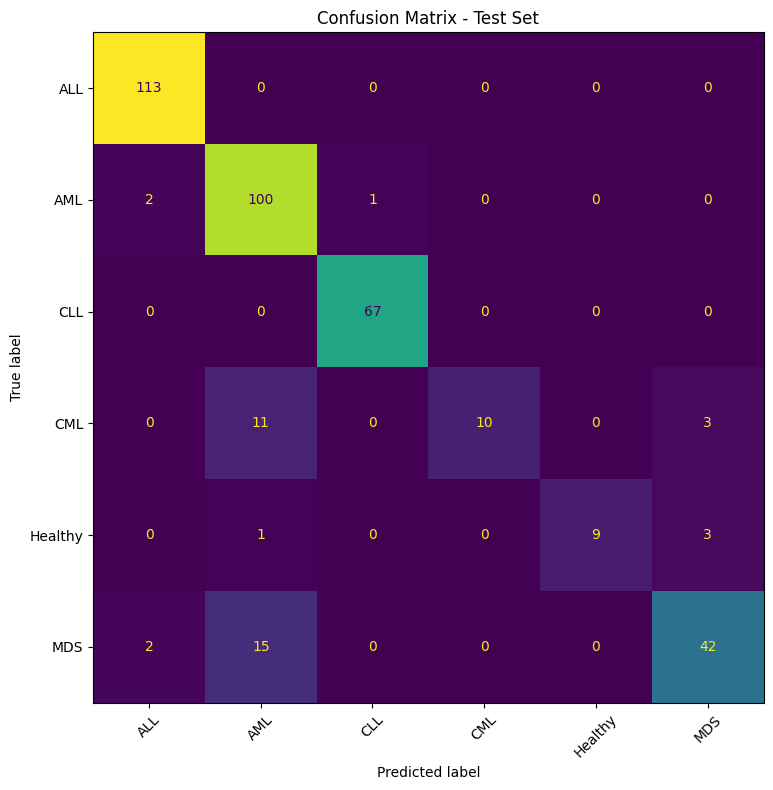

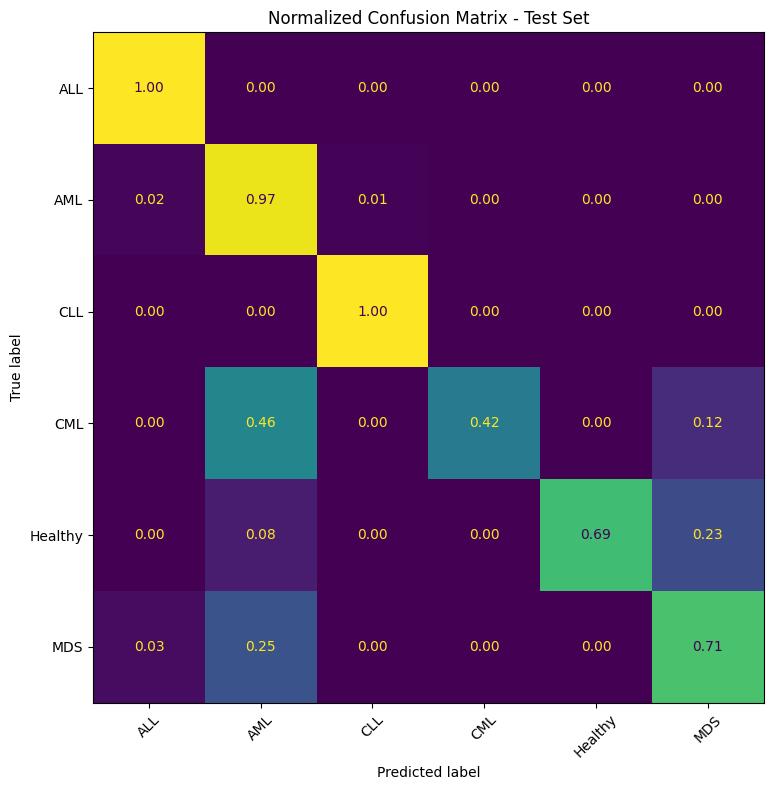

In [8]:

cm = confusion_matrix(y_test, test_pred)
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(METRIC_DIR / "confusion_matrix_test.csv")

fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Confusion Matrix - Test Set")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix_test.png", dpi=300, bbox_inches="tight")
plt.show()

cm_norm = confusion_matrix(y_test, test_pred, normalize="true")
fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, colorbar=False, values_format=".2f")
plt.title("Normalized Confusion Matrix - Test Set")
plt.tight_layout()
plt.savefig(FIG_DIR / "normalized_confusion_matrix_test.png", dpi=300, bbox_inches="tight")
plt.show()


### Bước 9. Kết quả đặc trưng của Random Forest

Random Forest có thể cho ra:
- feature importance của từng gene
- một số thống kê cấu trúc của rừng cây


In [9]:

importances = rf_model.feature_importances_
order = np.argsort(importances)[::-1]

importance_df = pd.DataFrame({
    "gene": [selected_gene_names[i] for i in order],
    "feature_importance": importances[order]
})
display(importance_df.head(30))
importance_df.to_csv(METRIC_DIR / "top_genes_feature_importance.csv", index=False)

forest_summary = pd.DataFrame([{
    "n_estimators": len(rf_model.estimators_),
    "max_depth_mean": float(np.mean([est.tree_.max_depth for est in rf_model.estimators_])),
    "n_nodes_mean": float(np.mean([est.tree_.node_count for est in rf_model.estimators_]))
}])
display(forest_summary)
forest_summary.to_csv(METRIC_DIR / "forest_structure_summary.csv", index=False)


,gene,feature_importance
0,ZNRF1,0.008214
1,LINC02273,0.007607
2,RALGPS2,0.006901
3,GP6,0.006803
4,PIGR,0.006394
5,MAP4K3-DT,0.006386
6,ATP2A1-AS1,0.006338
7,GAL3ST4,0.006332
8,NACA4P,0.006306
9,KCNE2,0.006292


,n_estimators,max_depth_mean,n_nodes_mean
0,400,14.135,267.035


### Bước 10. Nhận xét sơ bộ

In [10]:

test_row = summary_df[summary_df["split"] == "test"].iloc[0]

print("=" * 60)
print("NHẬN XÉT SƠ BỘ - RANDOM FOREST")
print("=" * 60)
print(f"Accuracy test: {float(test_row['accuracy']):.4f}")
print(f"Macro Precision test: {float(test_row['macro_precision']):.4f}")
print(f"Macro Recall test: {float(test_row['macro_recall']):.4f}")
print(f"Macro F1 test: {float(test_row['macro_f1']):.4f}")
print(f"AUC macro OVR test: {float(test_row['auc_macro_ovr']):.4f}")
print("- Random Forest là baseline ML mạnh, dễ dùng và có thể xem feature importance trực tiếp.")
print("- File top_genes_feature_importance giúp phân tích gene quan trọng theo góc nhìn của mô hình cây.")
print("- Nếu deep learning vượt rõ baseline này thì nhóm có cơ sở tốt để chứng minh giá trị mô hình đề xuất.")


NHẬN XÉT SƠ BỘ - RANDOM FOREST
Accuracy test: 0.8997
Macro Precision test: 0.9356
Macro Recall test: 0.7986
Macro F1 test: 0.8394
AUC macro OVR test: 0.9916
- Random Forest là baseline ML mạnh, dễ dùng và có thể xem feature importance trực tiếp.
- File top_genes_feature_importance giúp phân tích gene quan trọng theo góc nhìn của mô hình cây.
- Nếu deep learning vượt rõ baseline này thì nhóm có cơ sở tốt để chứng minh giá trị mô hình đề xuất.
